# 03 - Supervised Learning: Startup Success Score

**Professional analysis:** model comparison (Logistic Regression, KNN, Random Forest), probability calibration, a success score out of 100, factor explanations, and what-if scenarios.

This notebook answers two investor questions using startups with a known outcome:

1. **Classification:** How likely is a startup to succeed, as a score out of 100?
2. **Explanation:** Which factors raised or lowered that score, and how would it change if one thing changed?

`status`, `name` and `jobs` are never used as features, because they give the answer away. The model learns only from `num_founders`, `team_size`, `founded_year`, `industry` and `region`, with `label` as the target.

## 1. Load the data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.metrics import f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

In [4]:
# the project folders, or yc_clean.csv / predict.py uploaded next to the notebook (Colab)
DATA_PATH = next((p for p in [Path('../data/processed/yc_clean.csv'), Path('data/processed/yc_clean.csv'),
                              Path('yc_clean.csv')] if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('yc_clean.csv not found. In Colab, upload it with the folder icon on the left.')
MODELS_DIR = next((p for p in [Path('../models'), Path('models')] if p.exists()), Path('.'))

df = pd.read_csv(DATA_PATH)

cat_cols = ['industry', 'region']
num_cols = ['num_founders', 'team_size', 'founded_year']
features = cat_cols + num_cols

X = df[features]
y = df['label']
print(df.shape)
y.value_counts()

(2559, 12)


,count
label,
1,1874
0,685


## 2. Split
80% train, 20% test. `stratify=y` keeps the 73/27 balance in both parts.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(len(X_train), len(X_test))

2047 512


## 3. Pipeline
One-hot for the text columns and `StandardScaler` for the numbers. `team_size` goes from 1 to 8,600, so we take its log first. Everything is inside the Pipeline, so the app can pass raw values.

In [6]:
log_scale = Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                      ('scale', StandardScaler())])

preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), ['num_founders', 'founded_year']),
    ('team', log_scale, ['team_size']),
])

def build_model(model):
    # clone, so each model gets its own copy of the preprocessing
    return Pipeline([('preprocess', clone(preprocess)), ('model', model)])

### One startup to follow
To see how each model works, we follow one new startup through all three models.

The probabilities in sections 4-6 are lower than the final score, because balancing the classes pushes every model toward "failure". Section 9 fixes this with calibration, and the same startup ends with a score of 52.

In [7]:
example = pd.DataFrame([{'industry': 'Consumer', 'region': 'Middle East', 'num_founders': 1,
                         'team_size': 3, 'founded_year': 2019}])
example

,industry,region,num_founders,team_size,founded_year
0,Consumer,Middle East,1,3,2019


## 4. Logistic Regression (with `team_size`)
**How it works:** during training, Logistic Regression gives every column a weight (coefficient). To score a startup it adds up points:

`points = intercept + w(industry) + w(region) + w(num_founders) x num_founders + w(team_size) x team_size + w(founded_year) x founded_year`

- `industry` and `region` are one-hot columns, so only the startup's own category adds its weight (for example `industry_Consumer`).
- `num_founders`, `team_size` (after log) and `founded_year` are scaled, so 0 means average. A value above average multiplies its weight up, below average multiplies it down.
- The sigmoid function turns the total into a probability: a large positive total is close to 1 (success), a large negative total is close to 0 (failure).

Training adjusts the weights again and again until the probabilities match `label` as well as possible. `class_weight='balanced'` makes each failure count more, because failures are only 27% of the data.

In [8]:
lr_model = build_model(LogisticRegression(class_weight='balanced', max_iter=1000))
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
lr_proba = lr_model.predict_proba(X_test)[:, 1]

print('F1 (failure):', round(f1_score(y_test, lr_pred, pos_label=0), 3))
print('ROC-AUC:', round(roc_auc_score(y_test, lr_proba), 3))
print(classification_report(y_test, lr_pred))

F1 (failure): 0.642
ROC-AUC: 0.836
              precision    recall  f1-score   support

           0       0.52      0.84      0.64       137
           1       0.92      0.72      0.81       375

    accuracy                           0.75       512
   macro avg       0.72      0.78      0.73       512
weighted avg       0.82      0.75      0.76       512



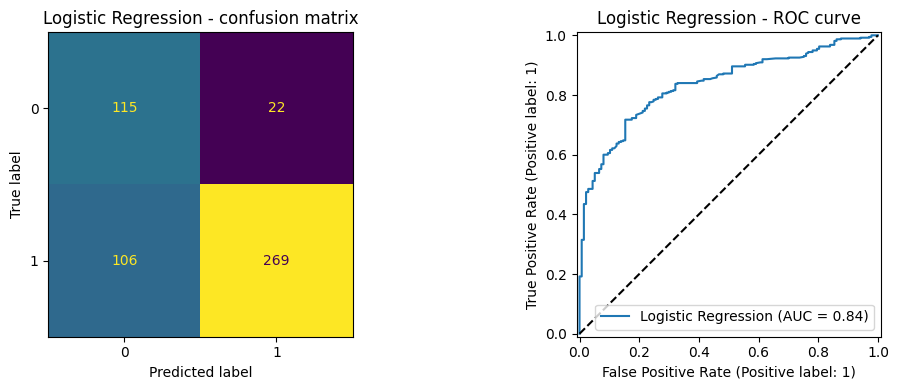

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, ax=axes[0], colorbar=False)
axes[0].set_title('Logistic Regression - confusion matrix')
RocCurveDisplay.from_predictions(y_test, lr_proba, name='Logistic Regression', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('Logistic Regression - ROC curve')
plt.tight_layout()
plt.show()

### The example startup, step by step
Only the columns the startup has are shown: its own industry and region, and the three numbers.

In [10]:
names = lr_model.named_steps['preprocess'].get_feature_names_out()
values = lr_model.named_steps['preprocess'].transform(example).toarray()[0]
weights = lr_model.named_steps['model'].coef_[0]

points = pd.DataFrame({'column': names, 'value': values, 'weight': weights, 'points': values * weights})
points['column'] = points['column'].str.split('__').str[1]
points = points[points['value'] != 0]
display(points.round(2))

intercept = lr_model.named_steps['model'].intercept_[0]
total = intercept + points['points'].sum()
probability = 1 / (1 + np.exp(-total))
print(f'intercept {intercept:.2f} + points {points["points"].sum():.2f} = total {total:.2f}')
print(f'sigmoid(total) = {probability:.2f}  |  model.predict_proba = {lr_model.predict_proba(example)[0][1]:.2f}')

,column,value,weight,points
1,industry_Consumer,1.00,-0.55,-0.55
12,region_Middle East,1.00,-0.08,-0.08
15,num_founders,-1.14,-0.10,0.12
16,founded_year,1.13,0.39,0.44
17,team_size,-0.95,1.50,-1.42


intercept 0.52 + points -1.50 = total -0.98
sigmoid(total) = 0.27  |  model.predict_proba = 0.27


## 5. KNN (with `team_size`)
**How it works:** KNN does not learn weights. It keeps every training startup in memory as a point, described by the same columns: one-hot `industry` and `region`, and scaled `num_founders`, `team_size` and `founded_year`. For a new startup it:
1. measures the distance to every training startup (same industry and region, similar team size and year = closer),
2. takes the k closest ones (`n_neighbors`, we test which k is best below),
3. counts how many of them succeeded: 18 successes out of 31 neighbours means a probability of 0.58.

Scaling matters here: without it, `founded_year` (around 2015) would decide every distance on its own.

KNN does not support `class_weight`, so we balance the training data first: copy random failure rows until both classes are the same size.

In [11]:
train = X_train.assign(label=y_train)
failed = train[train['label'] == 0]
extra = failed.sample(len(train) - 2 * len(failed), replace=True, random_state=42)
train_balanced = pd.concat([train, extra])
print(train_balanced['label'].value_counts())

label
1    1499
0    1499
Name: count, dtype: int64


### Choosing k
A small k copies the few closest startups, so the model memorises the training data (overfitting). A very large k looks at almost everyone, so every startup gets the same answer (underfitting).

We test several values with 5-fold cross-validation on the training set only. For each k we compare the score on the data the model learned from (train) with the score on data it did not see (validation). A big gap means overfitting.

In [12]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for k in [1, 5, 15, 31, 51, 101, 151]:
    train_auc, val_auc = [], []
    for train_idx, val_idx in cv.split(X_train, y_train):
        # balance only the training part of the fold
        fold = X_train.iloc[train_idx].assign(label=y_train.iloc[train_idx])
        fold_failed = fold[fold['label'] == 0]
        fold = pd.concat([fold, fold_failed.sample(len(fold) - 2 * len(fold_failed), replace=True, random_state=42)])

        model = build_model(KNeighborsClassifier(n_neighbors=k))
        model.fit(fold[features], fold['label'])
        train_auc.append(roc_auc_score(y_train.iloc[train_idx], model.predict_proba(X_train.iloc[train_idx])[:, 1]))
        val_auc.append(roc_auc_score(y_train.iloc[val_idx], model.predict_proba(X_train.iloc[val_idx])[:, 1]))
    rows.append({'k': k, 'train ROC-AUC': np.mean(train_auc), 'validation ROC-AUC': np.mean(val_auc)})

k_results = pd.DataFrame(rows)
k_results['gap'] = k_results['train ROC-AUC'] - k_results['validation ROC-AUC']
k_results.round(3)

,k,train ROC-AUC,validation ROC-AUC,gap
0,1,0.927,0.656,0.271
1,5,0.913,0.746,0.167
2,15,0.863,0.789,0.073
3,31,0.840,0.801,0.040
4,51,0.828,0.801,0.027
5,101,0.825,0.812,0.013
6,151,0.821,0.810,0.011


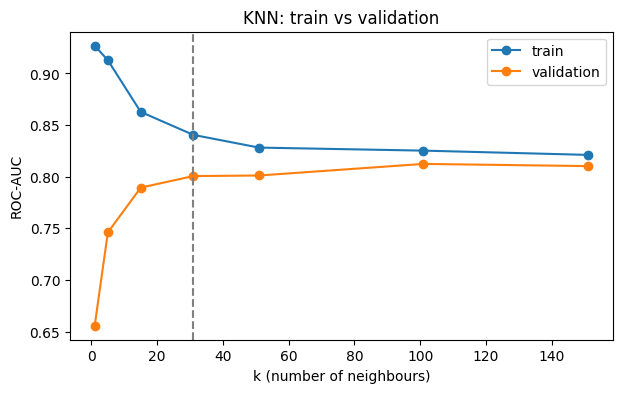

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(k_results['k'], k_results['train ROC-AUC'], marker='o', label='train')
plt.plot(k_results['k'], k_results['validation ROC-AUC'], marker='o', label='validation')
plt.axvline(31, color='gray', linestyle='--')
plt.xlabel('k (number of neighbours)')
plt.ylabel('ROC-AUC')
plt.title('KNN: train vs validation')
plt.legend()
plt.show()

k = 1 and k = 5 have a big gap between train and validation, so they overfit. From k = 31 the gap gets small and validation stops improving much. We pick **k = 31**: its validation score (0.801) is almost the same as k = 51 (0.802) and close to the best one (0.812 at k = 101), the gap is small (0.039), and it is the smallest k that reaches this level. It is also an odd number, so the vote between success and failure can never be a tie.

In [14]:
knn_model = build_model(KNeighborsClassifier(n_neighbors=31))
knn_model.fit(train_balanced[features], train_balanced['label'])

knn_pred = knn_model.predict(X_test)
knn_proba = knn_model.predict_proba(X_test)[:, 1]

print('F1 (failure):', round(f1_score(y_test, knn_pred, pos_label=0), 3))
print('ROC-AUC:', round(roc_auc_score(y_test, knn_proba), 3))
print(classification_report(y_test, knn_pred))

F1 (failure): 0.593
ROC-AUC: 0.818
              precision    recall  f1-score   support

           0       0.48      0.79      0.59       137
           1       0.90      0.68      0.78       375

    accuracy                           0.71       512
   macro avg       0.69      0.74      0.68       512
weighted avg       0.79      0.71      0.73       512



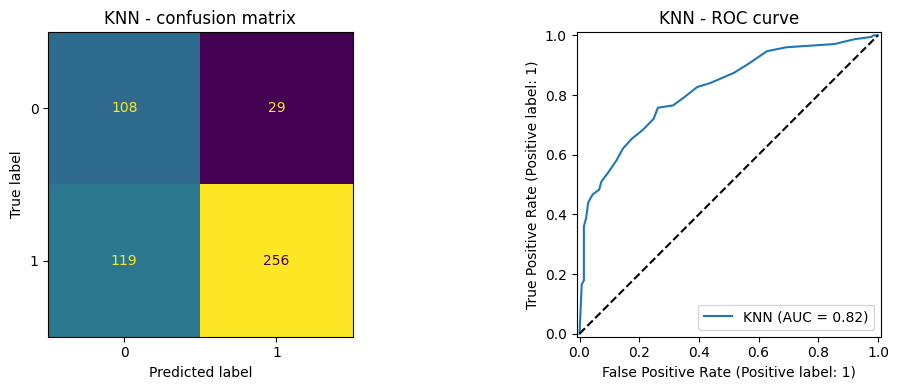

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, knn_pred, ax=axes[0], colorbar=False)
axes[0].set_title('KNN - confusion matrix')
RocCurveDisplay.from_predictions(y_test, knn_proba, name='KNN', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('KNN - ROC curve')
plt.tight_layout()
plt.show()

### The example startup and its 31 neighbours
The table shows the 15 closest. Some failed startups can appear more than once, because of the copies added to balance the data.

In [16]:
x = knn_model.named_steps['preprocess'].transform(example)
distances, idx = knn_model.named_steps['model'].kneighbors(x)

neighbours = train_balanced.iloc[idx[0]].copy()
neighbours.insert(0, 'name', df.loc[neighbours.index, 'name'])
neighbours['distance'] = distances[0].round(2)
display(neighbours.head(15))
print(f"{neighbours['label'].sum()} of {len(neighbours)} neighbours succeeded -> probability {knn_model.predict_proba(example)[0][1]:.2f}")

,name,industry,region,num_founders,team_size,founded_year,label,distance
800,Guggy,Consumer,Middle East,2,2,2017,0,1.38
800,Guggy,Consumer,Middle East,2,2,2017,0,1.38
800,Guggy,Consumer,Middle East,2,2,2017,0,1.38
314,Vectordash,Consumer,United States,1,3,2019,0,1.41
314,Vectordash,Consumer,United States,1,3,2019,0,1.41
2014,Lovd,Consumer,United States,1,4,2019,1,1.42
393,SciTok,Consumer,United States,1,2,2019,1,1.43
378,The Juggernaut,Consumer,United States,1,5,2019,1,1.44
36,Glimpse,Consumer,United States,1,5,2019,1,1.44
516,The Buttermilk Company,Consumer,United States,1,3,2018,0,1.45


7 of 31 neighbours succeeded -> probability 0.23


## 6. Random Forest (with `team_size`)
**How it works:** a Random Forest is 300 decision trees (`n_estimators=300`). Each tree is trained on a random sample of the training startups and asks yes/no questions about the columns, for example:
- is `team_size` small?
- is `industry_Consumer` = 1?
- is `founded_year` before a certain year?

At each step the tree picks the question that best separates successes from failures in its sample, and keeps splitting until a group would have fewer than 5 startups (`min_samples_leaf=5`). Each final group (leaf) stores its share of successes.

For a new startup, every tree sends it down its questions to one leaf, and the forest averages the 300 answers. Because each tree saw different startups, each one asks slightly different questions.

In [17]:
rf_model = build_model(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                             class_weight='balanced', random_state=42))
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print('F1 (failure):', round(f1_score(y_test, rf_pred, pos_label=0), 3))
print('ROC-AUC:', round(roc_auc_score(y_test, rf_proba), 3))
print(classification_report(y_test, rf_pred))

F1 (failure): 0.63
ROC-AUC: 0.848
              precision    recall  f1-score   support

           0       0.52      0.80      0.63       137
           1       0.91      0.73      0.81       375

    accuracy                           0.75       512
   macro avg       0.71      0.77      0.72       512
weighted avg       0.81      0.75      0.76       512



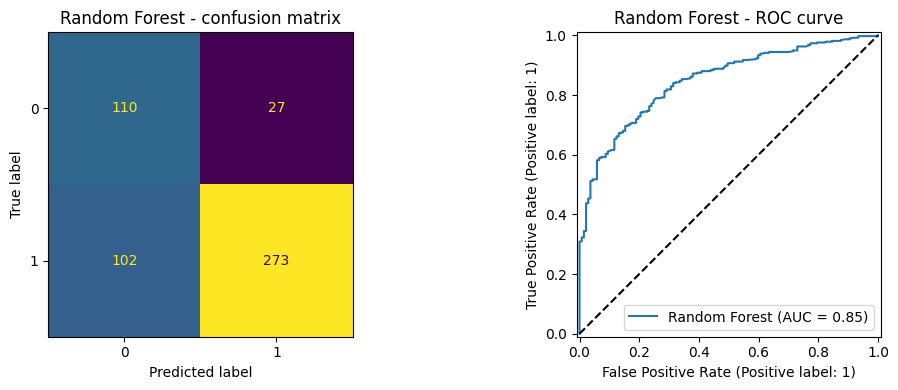

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, ax=axes[0], colorbar=False)
axes[0].set_title('Random Forest - confusion matrix')
RocCurveDisplay.from_predictions(y_test, rf_proba, name='Random Forest', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('Random Forest - ROC curve')
plt.tight_layout()
plt.show()

### One of the 300 trees (first 2 levels)
How to read it: `industry_Consumer <= 0.5` means "not Consumer" (True goes left). Numbers like `team_size <= -0.176` are after scaling, where 0 is the average. `value` is the share of failures and successes in that group.

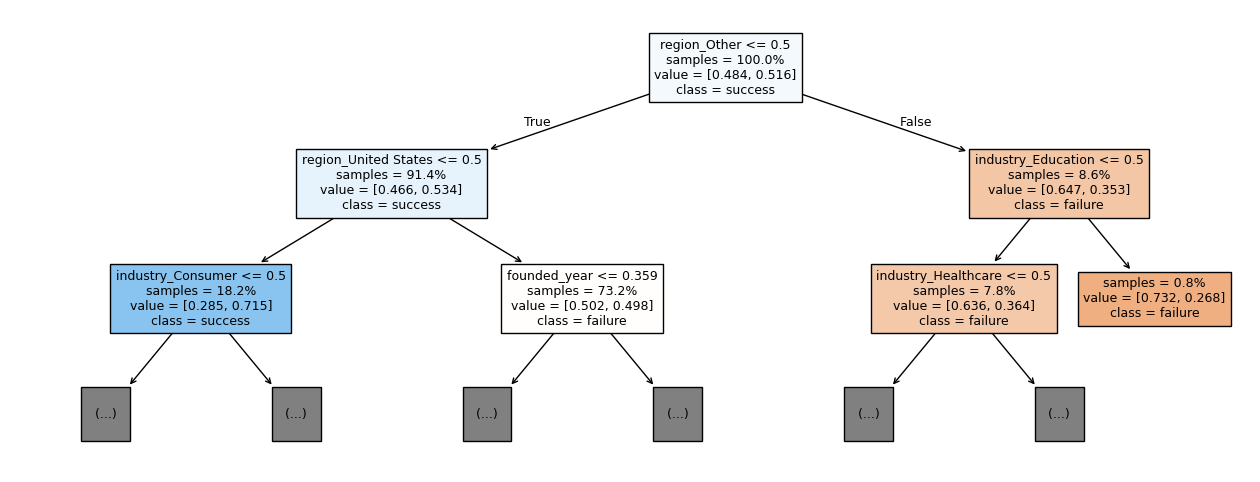

In [19]:
tree_names = rf_model.named_steps['preprocess'].get_feature_names_out()
tree_names = [n.split('__')[1] for n in tree_names]
first_tree = rf_model.named_steps['model'].estimators_[0]

plt.figure(figsize=(16, 6))
plot_tree(first_tree, max_depth=2, feature_names=tree_names, class_names=['failure', 'success'],
          filled=True, impurity=False, proportion=True, fontsize=9)
plt.show()

### What the 300 trees say about the example startup

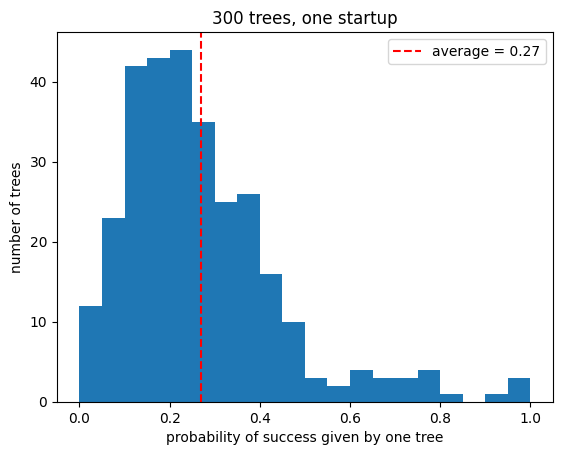

model.predict_proba = 0.27


In [20]:
x = rf_model.named_steps['preprocess'].transform(example)
tree_answers = [tree.predict_proba(x)[0][1] for tree in rf_model.named_steps['model'].estimators_]

plt.hist(tree_answers, bins=20)
plt.axvline(np.mean(tree_answers), color='red', linestyle='--', label=f'average = {np.mean(tree_answers):.2f}')
plt.xlabel('probability of success given by one tree')
plt.ylabel('number of trees')
plt.title('300 trees, one startup')
plt.legend()
plt.show()
print(f'model.predict_proba = {rf_model.predict_proba(example)[0][1]:.2f}')

## 7. Compare the 3 models (with `team_size`)

In [21]:
comparison = pd.DataFrame({
    'F1 (failure)': [f1_score(y_test, lr_pred, pos_label=0), f1_score(y_test, knn_pred, pos_label=0), f1_score(y_test, rf_pred, pos_label=0)],
    'F1 (success)': [f1_score(y_test, lr_pred), f1_score(y_test, knn_pred), f1_score(y_test, rf_pred)],
    'ROC-AUC': [roc_auc_score(y_test, lr_proba), roc_auc_score(y_test, knn_proba), roc_auc_score(y_test, rf_proba)],
}, index=['Logistic Regression', 'KNN', 'Random Forest'])
comparison.round(3)

,F1 (failure),F1 (success),ROC-AUC
Logistic Regression,0.642,0.808,0.836
KNN,0.593,0.776,0.818
Random Forest,0.630,0.809,0.848


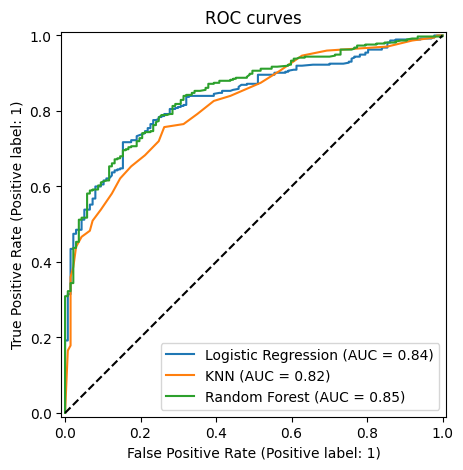

In [22]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, lr_proba, name='Logistic Regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, knn_proba, name='KNN', ax=ax)
RocCurveDisplay.from_predictions(y_test, rf_proba, name='Random Forest', ax=ax)
ax.plot([0, 1], [0, 1], 'k--')
ax.set_title('ROC curves')
plt.show()

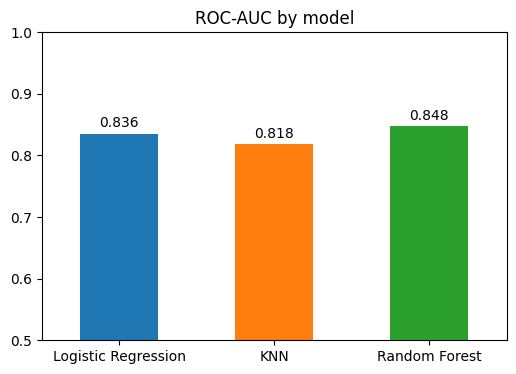

In [23]:
ax = comparison['ROC-AUC'].plot.bar(rot=0, color=['tab:blue', 'tab:orange', 'tab:green'], figsize=(6, 4))
ax.set_title('ROC-AUC by model')
ax.set_ylim(0.5, 1)
for i, v in enumerate(comparison['ROC-AUC']):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center')
plt.show()

Random Forest has the best ROC-AUC (0.848), but Logistic Regression is very close (0.836) and has the best F1 for failures (0.642). KNN with k = 31 has the lowest scores on both (0.820 and 0.593). We pick **Logistic Regression**: the results are almost the same as Random Forest, and its coefficients explain the score directly.

## 8. Without `team_size`
The data guide warns that `team_size` is the size today, so a dead company shows its last small team. Here we train the same 3 models again, with the same settings, on the other 4 features only.

In [24]:
features_no_team = ['industry', 'region', 'num_founders', 'founded_year']
X_train_no_team = X_train[features_no_team]
X_test_no_team = X_test[features_no_team]

preprocess_no_team = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), ['num_founders', 'founded_year']),
])

def build_model_no_team(model):
    return Pipeline([('preprocess', clone(preprocess_no_team)), ('model', model)])

### 8.1 Logistic Regression without `team_size`

In [25]:
lr_no_team = build_model_no_team(LogisticRegression(class_weight='balanced', max_iter=1000))
lr_no_team.fit(X_train_no_team, y_train)

lr_no_team_pred = lr_no_team.predict(X_test_no_team)
lr_no_team_proba = lr_no_team.predict_proba(X_test_no_team)[:, 1]

print('F1 (failure):', round(f1_score(y_test, lr_no_team_pred, pos_label=0), 3))
print('ROC-AUC:', round(roc_auc_score(y_test, lr_no_team_proba), 3))
print(classification_report(y_test, lr_no_team_pred))

F1 (failure): 0.472
ROC-AUC: 0.669
              precision    recall  f1-score   support

           0       0.37      0.64      0.47       137
           1       0.82      0.61      0.70       375

    accuracy                           0.62       512
   macro avg       0.60      0.62      0.58       512
weighted avg       0.70      0.62      0.64       512



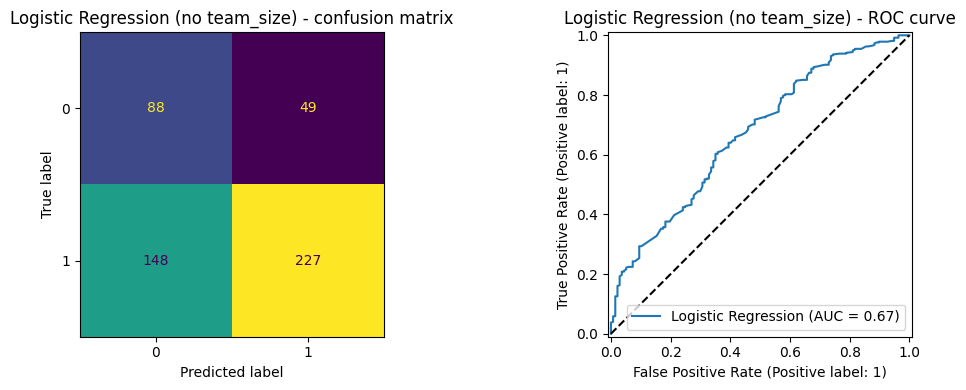

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, lr_no_team_pred, ax=axes[0], colorbar=False)
axes[0].set_title('Logistic Regression (no team_size) - confusion matrix')
RocCurveDisplay.from_predictions(y_test, lr_no_team_proba, name='Logistic Regression', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('Logistic Regression (no team_size) - ROC curve')
plt.tight_layout()
plt.show()

### 8.2 KNN without `team_size`
Same k = 31 and the same balanced training data.

In [27]:
knn_no_team = build_model_no_team(KNeighborsClassifier(n_neighbors=31))
knn_no_team.fit(train_balanced[features_no_team], train_balanced['label'])

knn_no_team_pred = knn_no_team.predict(X_test_no_team)
knn_no_team_proba = knn_no_team.predict_proba(X_test_no_team)[:, 1]

print('F1 (failure):', round(f1_score(y_test, knn_no_team_pred, pos_label=0), 3))
print('ROC-AUC:', round(roc_auc_score(y_test, knn_no_team_proba), 3))
print(classification_report(y_test, knn_no_team_pred))

F1 (failure): 0.416
ROC-AUC: 0.621
              precision    recall  f1-score   support

           0       0.33      0.57      0.42       137
           1       0.78      0.57      0.66       375

    accuracy                           0.57       512
   macro avg       0.56      0.57      0.54       512
weighted avg       0.66      0.57      0.60       512



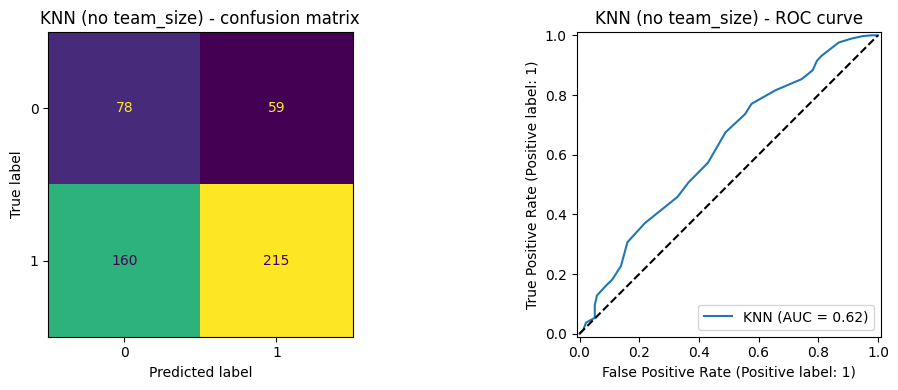

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, knn_no_team_pred, ax=axes[0], colorbar=False)
axes[0].set_title('KNN (no team_size) - confusion matrix')
RocCurveDisplay.from_predictions(y_test, knn_no_team_proba, name='KNN', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('KNN (no team_size) - ROC curve')
plt.tight_layout()
plt.show()

### 8.3 Random Forest without `team_size`

In [29]:
rf_no_team = build_model_no_team(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                        class_weight='balanced', random_state=42))
rf_no_team.fit(X_train_no_team, y_train)

rf_no_team_pred = rf_no_team.predict(X_test_no_team)
rf_no_team_proba = rf_no_team.predict_proba(X_test_no_team)[:, 1]

print('F1 (failure):', round(f1_score(y_test, rf_no_team_pred, pos_label=0), 3))
print('ROC-AUC:', round(roc_auc_score(y_test, rf_no_team_proba), 3))
print(classification_report(y_test, rf_no_team_pred))

F1 (failure): 0.443
ROC-AUC: 0.666
              precision    recall  f1-score   support

           0       0.35      0.60      0.44       137
           1       0.80      0.60      0.69       375

    accuracy                           0.60       512
   macro avg       0.58      0.60      0.56       512
weighted avg       0.68      0.60      0.62       512



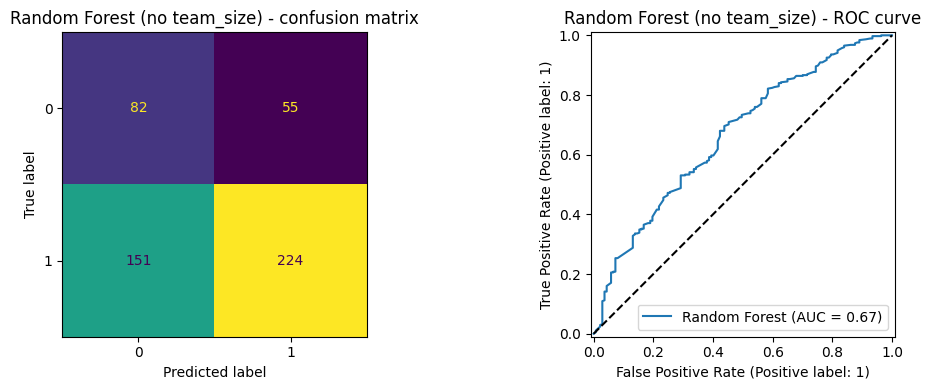

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, rf_no_team_pred, ax=axes[0], colorbar=False)
axes[0].set_title('Random Forest (no team_size) - confusion matrix')
RocCurveDisplay.from_predictions(y_test, rf_no_team_proba, name='Random Forest', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('Random Forest (no team_size) - ROC curve')
plt.tight_layout()
plt.show()

### 8.4 Compare: with vs without `team_size`

In [31]:
no_team = pd.DataFrame({
    'F1 (failure)': [f1_score(y_test, lr_no_team_pred, pos_label=0), f1_score(y_test, knn_no_team_pred, pos_label=0), f1_score(y_test, rf_no_team_pred, pos_label=0)],
    'F1 (success)': [f1_score(y_test, lr_no_team_pred), f1_score(y_test, knn_no_team_pred), f1_score(y_test, rf_no_team_pred)],
    'ROC-AUC': [roc_auc_score(y_test, lr_no_team_proba), roc_auc_score(y_test, knn_no_team_proba), roc_auc_score(y_test, rf_no_team_proba)],
}, index=['Logistic Regression', 'KNN', 'Random Forest'])

pd.concat({'with team_size': comparison, 'without team_size': no_team}, axis=1).round(3)

with team_size                      without team_size  \
                      F1 (failure) F1 (success) ROC-AUC      F1 (failure)   
Logistic Regression          0.642        0.808   0.836             0.472   
KNN                          0.593        0.776   0.818             0.416   
Random Forest                0.630        0.809   0.848             0.443   

                                          
                    F1 (success) ROC-AUC  
Logistic Regression        0.697   0.669  
KNN                        0.663   0.621  
Random Forest              0.685   0.666

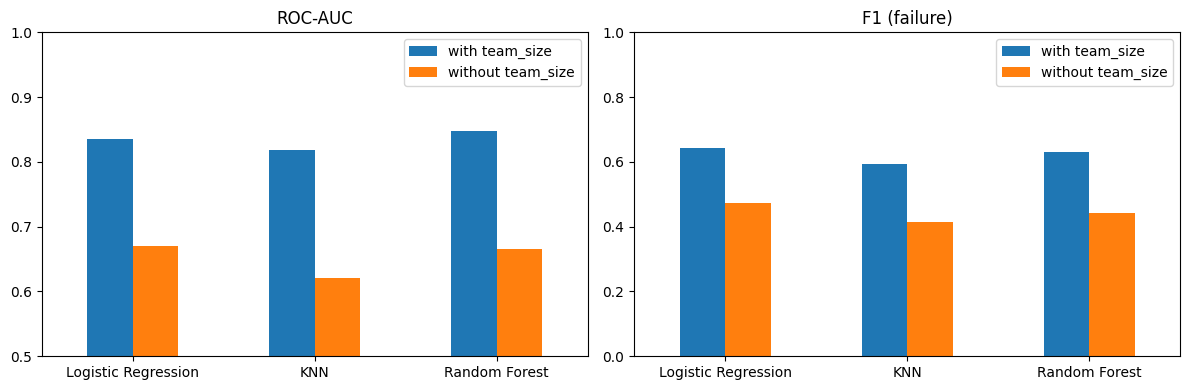

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.DataFrame({'with team_size': comparison['ROC-AUC'], 'without team_size': no_team['ROC-AUC']}).plot.bar(ax=axes[0], rot=0)
axes[0].set_title('ROC-AUC')
axes[0].set_ylim(0.5, 1)
pd.DataFrame({'with team_size': comparison['F1 (failure)'], 'without team_size': no_team['F1 (failure)']}).plot.bar(ax=axes[1], rot=0)
axes[1].set_title('F1 (failure)')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

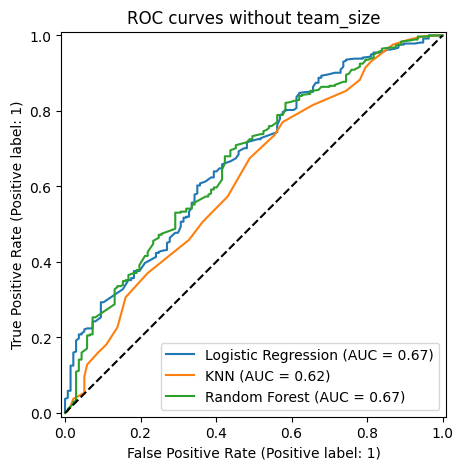

In [33]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, lr_no_team_proba, name='Logistic Regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, knn_no_team_proba, name='KNN', ax=ax)
RocCurveDisplay.from_predictions(y_test, rf_no_team_proba, name='Random Forest', ax=ax)
ax.plot([0, 1], [0, 1], 'k--')
ax.set_title('ROC curves without team_size')
plt.show()

All three models drop a lot without `team_size`: ROC-AUC falls from about 0.83 to about 0.65, and F1 for failures from about 0.62 to about 0.45. So most of the models' power comes from this one column.

Without `team_size`, **Logistic Regression is the best model on both metrics** (F1 0.472, ROC-AUC 0.669). Random Forest loses its lead, because its strength came from splitting `team_size` finely.

### 8.5 Hyperparameter tuning: best model without `team_size`
Logistic Regression is the best model without `team_size`, so we tune it. Its main setting is `C`, the strength of regularization: a small `C` keeps the weights small and simple, a large `C` lets them grow to fit the training data more closely.

We try several values with `GridSearchCV` and 5-fold cross-validation on the training set only, then check the winner once on the test set.

In [34]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    build_model_no_team(LogisticRegression(class_weight='balanced', max_iter=1000)),
    param_grid={'model__C': [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=cv,
    scoring='roc_auc',
)
search.fit(X_train_no_team, y_train)

pd.DataFrame({'C': search.cv_results_['param_model__C'],
              'CV ROC-AUC': search.cv_results_['mean_test_score']}).round(3)

,C,CV ROC-AUC
0,0.001,0.652
1,0.010,0.662
2,0.100,0.667
3,1.000,0.667
4,10.000,0.666
5,100.000,0.666


In [35]:
lr_tuned = search.best_estimator_
lr_tuned_pred = lr_tuned.predict(X_test_no_team)
lr_tuned_proba = lr_tuned.predict_proba(X_test_no_team)[:, 1]

print('best C:', search.best_params_['model__C'])
pd.DataFrame({
    'F1 (failure)': [f1_score(y_test, lr_no_team_pred, pos_label=0), f1_score(y_test, lr_tuned_pred, pos_label=0)],
    'ROC-AUC': [roc_auc_score(y_test, lr_no_team_proba), roc_auc_score(y_test, lr_tuned_proba)],
}, index=['default (C = 1)', 'tuned']).round(3)

best C: 0.1


,F1 (failure),ROC-AUC
default (C = 1),0.472,0.669
tuned,0.477,0.671


The best value is `C = 0.1`, but every value from 0.01 to 100 gives almost the same CV ROC-AUC (0.662 to 0.667). On the test set the tuned model improves only a little: F1 for failures 0.472 → 0.477 and ROC-AUC 0.669 → 0.671.

So tuning does not really change the result. The limit is not the model's settings but the information in the 4 features: without `team_size`, the data alone cannot separate successes from failures much better than about 0.67.

## 9. The score
Calibrate the probabilities, then `score = probability * 100`.
Tiers: 70+ Strong signal, 40-69 Needs review, below 40 Weak signal.

In [36]:
final_model = CalibratedClassifierCV(build_model(LogisticRegression(class_weight='balanced', max_iter=1000)), cv=5)
final_model.fit(X_train, y_train)

def get_tier(score):
    if score >= 70:
        return 'Strong signal'
    if score >= 40:
        return 'Needs review'
    return 'Weak signal'

scores = (final_model.predict_proba(X_test)[:, 1] * 100).round()
print('ROC-AUC after calibration:', round(roc_auc_score(y_test, scores), 3))
pd.Series(scores).apply(get_tier).value_counts()

ROC-AUC after calibration: 0.836


,count
Strong signal,315
Needs review,137
Weak signal,60


## 10. Most important factors
Logistic Regression coefficients: positive raises the score, negative lowers it.

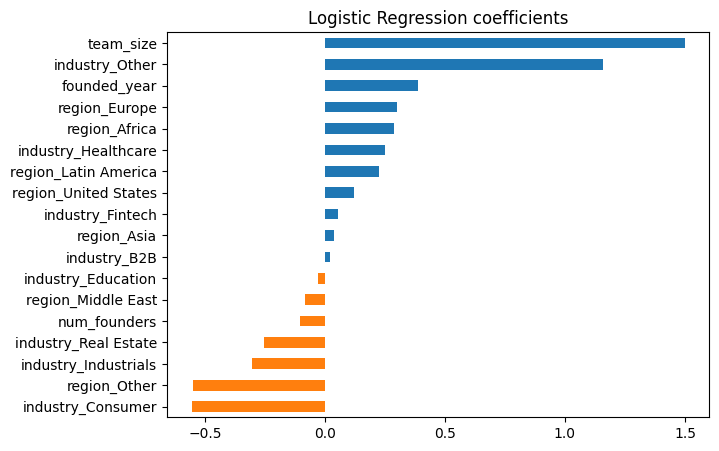

In [37]:
names = lr_model.named_steps['preprocess'].get_feature_names_out()
coefs = pd.Series(lr_model.named_steps['model'].coef_[0], index=names).sort_values()
coefs.index = coefs.index.str.split('__').str[1]

coefs.plot.barh(figsize=(7, 5), color=np.where(coefs > 0, 'tab:blue', 'tab:orange'),
                title='Logistic Regression coefficients')
plt.show()

`team_size` has the biggest effect. Consumer and region `Other` lower the score the most. `industry_Other` looks big, but it is only 40 companies.

### Factors for one startup
For each feature, we put back the value of a typical startup and see how much the score changes. With Logistic Regression this change comes only from that feature's coefficient, so a positive coefficient pushes the score up and a negative one pushes it down.
Groups: team (founders, team size), market (industry), ecosystem (region, year).

In [38]:
# typical startup = most common category / median number in the training data
typical = {'industry': X_train['industry'].mode()[0],
           'region': X_train['region'].mode()[0],
           'num_founders': int(X_train['num_founders'].median()),
           'team_size': int(X_train['team_size'].median()),
           'founded_year': int(X_train['founded_year'].median())}
print('typical startup:', typical)

groups = {'num_founders': 'team', 'team_size': 'team', 'industry': 'market',
          'region': 'ecosystem', 'founded_year': 'ecosystem'}

def get_score(startup):
    row = pd.DataFrame([startup])[features]
    return final_model.predict_proba(row)[0][1] * 100

def get_factors(startup):
    score = get_score(startup)
    factors = []
    for f in features:
        changed = {**startup, f: typical[f]}
        factors.append({'group': groups[f], 'feature': f, 'value': startup[f],
                        'impact': round(score - get_score(changed))})
    print('score:', round(score), get_tier(round(score)))
    return pd.DataFrame(factors)

startup = {'industry': 'Consumer', 'region': 'Middle East', 'num_founders': 1, 'team_size': 3, 'founded_year': 2019}
get_factors(startup)

typical startup: {'industry': 'B2B', 'region': 'United States', 'num_founders': 2, 'team_size': 11, 'founded_year': 2016}
score: 52 Needs review


,group,feature,value,impact
0,market,industry,Consumer,-13
1,ecosystem,region,Middle East,-5
2,team,num_founders,1,3
3,team,team_size,3,-23
4,ecosystem,founded_year,2019,8


## 11. What-if

In [39]:
def what_if(startup, change):
    before = round(get_score(startup))
    after = round(get_score({**startup, **change}))
    print(f'{change}: {before} -> {after}')

what_if(startup, {'num_founders': 2})
what_if(startup, {'team_size': 6})
what_if(startup, {'industry': 'Fintech'})

{'num_founders': 2}: 52 -> 49
{'team_size': 6}: 52 -> 64
{'industry': 'Fintech'}: 52 -> 65


## 12. Save

## Final conclusion

- **Representation:** one-hot encoding keeps industry and region information; `log1p` and StandardScaler stop `team_size` (1 to 8,600) from dominating KNN distances and the Logistic Regression coefficients. Everything is inside one Pipeline, so the app can pass raw values.
- **Class imbalance:** the data is 73% success, so Logistic Regression and Random Forest use `class_weight='balanced'`, KNN is trained on oversampled data, and models are compared with F1 and ROC-AUC instead of accuracy.
- **Model choice:** Random Forest has the highest ROC-AUC (0.848), but Logistic Regression is very close (0.836) and has the best F1 for failures (0.642). Logistic Regression is selected because its coefficients explain the score directly.
- **Score:** probabilities are calibrated with `CalibratedClassifierCV`, then `score = probability x 100` and split into Strong signal (70+), Needs review (40-69) and Weak signal (below 40).
- **Factors:** `team_size` has the biggest effect, then industry (Consumer lowers the score the most) and founding year. Factors are grouped into team, market and ecosystem, and the what-if shows how the score changes when one feature changes.
- **Without `team_size`:** all three models drop to about 0.63-0.67 ROC-AUC. Logistic Regression is still the best (F1 for failures 0.472, ROC-AUC 0.669). Tuning its `C` with GridSearchCV gives only a very small gain (0.477 and 0.671), so the limit comes from the features, not the settings.
- **Important limitation:** `team_size` is the team size in November 2024, not at founding. Without it ROC-AUC drops to about 0.67, so most of the model's power comes from a column that partly reflects the outcome. The score should be read as a signal for review, not a final decision.